In [22]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Find project directory
current_dir = Path.cwd()

if (current_dir / "data" / "raw").exists():
    BASE_DIR = current_dir
elif (current_dir.parent / "data" / "raw").exists():
    BASE_DIR = current_dir.parent
else:
    raise FileNotFoundError("Cannot find the data/raw folder")

DATA_DIR = BASE_DIR / "data" / "raw"

print("Libraries imported successfully!")
print("Project directory:", BASE_DIR)
print("Dataset directory:", DATA_DIR)
print("Dataset folder exists:", DATA_DIR.exists())


Libraries imported successfully!
Project directory: c:\Users\admin\OneDrive\Enterprise_Demand_Forecasting
Dataset directory: c:\Users\admin\OneDrive\Enterprise_Demand_Forecasting\data\raw
Dataset folder exists: True


In [23]:

# Step 2: Load all three datasets

sales = pd.read_csv(DATA_DIR / "sales_train_validation.csv")

calendar = pd.read_csv(DATA_DIR / "calendar.csv")

prices = pd.read_csv(DATA_DIR / "sell_prices.csv")

print("All datasets loaded successfully!")

print("\nSales Dataset:", sales.shape)
print("Calendar Dataset:", calendar.shape)
print("Prices Dataset:", prices.shape)


All datasets loaded successfully!

Sales Dataset: (30490, 1919)
Calendar Dataset: (1969, 14)
Prices Dataset: (6841121, 4)


In [24]:

# Step 3: Convert wide sales data into long format

sales_sample = sales.head(5).melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=[f"d_{i}" for i in range(1, 8)],
    var_name="d",
    value_name="sales"
)

print("Transformed Dataset:")
display(sales_sample.head(10))

print("\nNew Dataset Shape:")
print(sales_sample.shape)


Transformed Dataset:


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
5,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0
6,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0
7,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0
8,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0
9,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0



New Dataset Shape:
(35, 8)


In [25]:

# Step 4: Merge sales data with calendar information

calendar_features = calendar[
    ["d", "date", "weekday", "month", "year",
     "event_name_1", "event_type_1"]
]

sales_with_calendar = sales_sample.merge(
    calendar_features,
    on="d",
    how="left"
)

print("Sales and Calendar merged successfully!")

print("\nFirst 10 rows:")
display(sales_with_calendar.head(10))

print("\nMerged Dataset Shape:")
print(sales_with_calendar.shape)

print("\nMissing dates:")
print(sales_with_calendar["date"].isnull().sum())


Sales and Calendar merged successfully!

First 10 rows:


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,weekday,month,year,event_name_1,event_type_1
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,Saturday,1,2011,NaN,NaN
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,Saturday,1,2011,NaN,NaN
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,Saturday,1,2011,NaN,NaN
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,Saturday,1,2011,NaN,NaN
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,Saturday,1,2011,NaN,NaN
5,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,Sunday,1,2011,NaN,NaN
6,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,Sunday,1,2011,NaN,NaN
7,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,Sunday,1,2011,NaN,NaN
8,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,Sunday,1,2011,NaN,NaN
9,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,Sunday,1,2011,NaN,NaN



Merged Dataset Shape:
(35, 14)

Missing dates:
0


In [26]:

# Step 5: Validate merged data

print("Total records:", len(sales_with_calendar))

print("\nDate range:")
print(sales_with_calendar["date"].min())
print(sales_with_calendar["date"].max())

print("\nSales by weekday:")
print(
    sales_with_calendar.groupby("weekday")["sales"]
    .sum()
)

print("\nMissing values:")
print(sales_with_calendar.isnull().sum())


Total records: 35

Date range:
2011-01-29
2011-02-04

Sales by weekday:
weekday
Friday       0
Monday       0
Saturday     0
Sunday       0
Thursday     0
Tuesday      0
Wednesday    0
Name: sales, dtype: int64

Missing values:
id               0
item_id          0
dept_id          0
cat_id           0
store_id         0
state_id         0
d                0
sales            0
date             0
weekday          0
month            0
year             0
event_name_1    35
event_type_1    35
dtype: int64


In [27]:

# Check sales for the first five products

print("Sales values for first five products:")

display(
    sales[
        ["item_id", "store_id", "d_1", "d_2",
         "d_3", "d_4", "d_5", "d_6", "d_7"]
    ].head()
)

print("\nTotal sales in sample:", sales_sample["sales"].sum())

print("Number of non-zero sales:", 
      (sales_sample["sales"] > 0).sum())


Sales values for first five products:


,item_id,store_id,d_1,d_2,d_3,d_4,d_5,d_6,d_7
0,HOBBIES_1_001,CA_1,0,0,0,0,0,0,0
1,HOBBIES_1_002,CA_1,0,0,0,0,0,0,0
2,HOBBIES_1_003,CA_1,0,0,0,0,0,0,0
3,HOBBIES_1_004,CA_1,0,0,0,0,0,0,0
4,HOBBIES_1_005,CA_1,0,0,0,0,0,0,0



Total sales in sample: 0
Number of non-zero sales: 0


In [28]:

# Check sales across the first 30 days

first_5_products = sales.head(5)

sales_30_days = [
    f"d_{i}" for i in range(1, 31)
]

print("Total sales during first 30 days:")

display(
    first_5_products[
        ["item_id", "store_id"] + sales_30_days
    ]
)

print("\nTotal units sold in first 30 days:")
print(first_5_products[sales_30_days].sum(axis=1))

print("\nNon-zero sales days:")
print((first_5_products[sales_30_days] > 0).sum(axis=1))


Total sales during first 30 days:


,item_id,store_id,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,...,d_21,d_22,d_23,d_24,d_25,d_26,d_27,d_28,d_29,d_30
0,HOBBIES_1_001,CA_1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,HOBBIES_1_002,CA_1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,HOBBIES_1_003,CA_1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,HOBBIES_1_004,CA_1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,HOBBIES_1_005,CA_1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Total units sold in first 30 days:
0    0
1    0
2    0
3    0
4    0
dtype: int64

Non-zero sales days:
0    0
1    0
2    0
3    0
4    0
dtype: int64


In [ ]:
# Use the fixed product roster monitored by this project.
PRODUCTS = ["FOODS_3_090", "FOODS_3_120", "FOODS_3_252", "FOODS_3_586", "FOODS_3_714"]
top_5_ca1 = sales.loc[
    sales["store_id"].eq("CA_1") & sales["item_id"].isin(PRODUCTS)
].copy()

display(top_5_ca1[["item_id", "store_id"]])

In [31]:
display(
    top_5_ca1[
        ["item_id"] + [f"d_{i}" for i in range(100, 131)]
    ]
)

,item_id,d_100,d_101,d_102,d_103,d_104,d_105,d_106,d_107,d_108,...,d_121,d_122,d_123,d_124,d_125,d_126,d_127,d_128,d_129,d_130
2314,FOODS_3_090,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2810,FOODS_3_586,54,36,19,28,34,62,51,68,33,...,55,48,39,34,46,45,58,57,55,41
2476,FOODS_3_252,29,24,10,21,19,23,33,36,15,...,55,23,15,15,31,29,40,39,25,15
2344,FOODS_3_120,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2937,FOODS_3_714,46,27,40,32,31,59,58,45,29,...,50,40,23,32,18,27,46,64,31,41


In [32]:
day_columns = [f"d_{i}" for i in range(1, 1914)]

for _, product in top_5_ca1.iterrows():
    nonzero_days = product[day_columns][product[day_columns] > 0]

    print(
        product["item_id"],
        "| First sale:", nonzero_days.index[0] if len(nonzero_days) > 0 else "No sales",
        "| Days with sales:", len(nonzero_days)
    )

FOODS_3_090 | First sale: d_1 | Days with sales: 1444
FOODS_3_586 | First sale: d_1 | Days with sales: 1906
FOODS_3_252 | First sale: d_1 | Days with sales: 1907
FOODS_3_120 | First sale: d_368 | Days with sales: 1246
FOODS_3_714 | First sale: d_1 | Days with sales: 1906


In [33]:
for _, product in top_5_ca1.iterrows():
    zero_days = (product[day_columns] == 0).sum()
    zero_percentage = (zero_days / len(day_columns)) * 100

    print(
        product["item_id"],
        "| Zero-sales days:", zero_days,
        "| Zero-sales percentage:", round(zero_percentage, 2), "%"
    )

FOODS_3_090 | Zero-sales days: 469 | Zero-sales percentage: 24.52 %
FOODS_3_586 | Zero-sales days: 7 | Zero-sales percentage: 0.37 %
FOODS_3_252 | Zero-sales days: 6 | Zero-sales percentage: 0.31 %
FOODS_3_120 | Zero-sales days: 667 | Zero-sales percentage: 34.87 %
FOODS_3_714 | Zero-sales days: 7 | Zero-sales percentage: 0.37 %


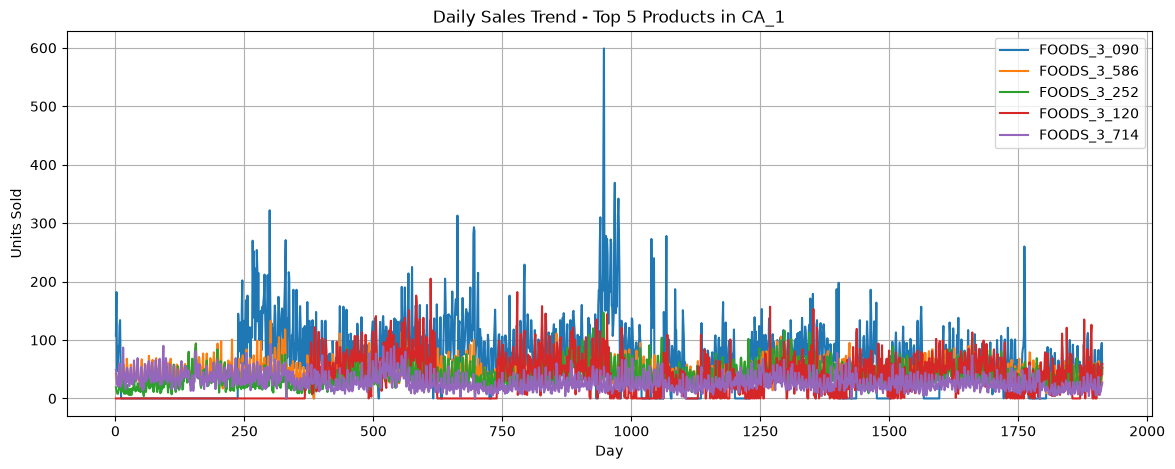

In [34]:
plt.figure(figsize=(14, 5))

for _, product in top_5_ca1.iterrows():
    plt.plot(
        range(1, 1914),
        product[day_columns].values,
        label=product["item_id"]
    )

plt.title("Daily Sales Trend - Top 5 Products in CA_1")
plt.xlabel("Day")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.show()

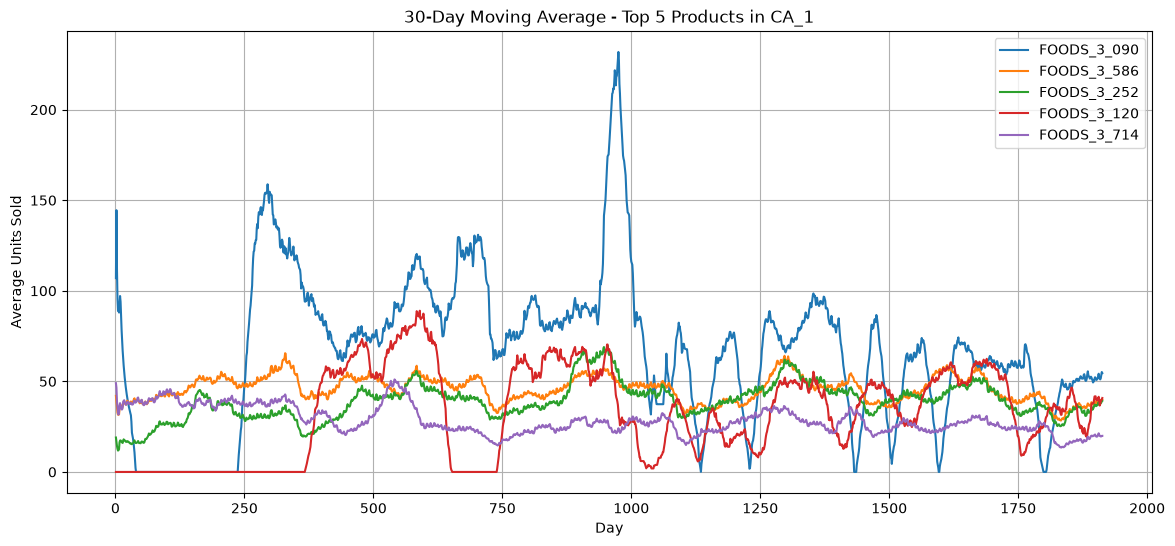

In [35]:
plt.figure(figsize=(14, 6))

for _, product in top_5_ca1.iterrows():
    daily_sales = product[day_columns].astype(float)

    rolling_sales = daily_sales.rolling(
        window=30,
        min_periods=1
    ).mean()

    plt.plot(
        range(1, 1914),
        rolling_sales,
        label=product["item_id"]
    )

plt.title("30-Day Moving Average - Top 5 Products in CA_1")
plt.xlabel("Day")
plt.ylabel("Average Units Sold")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
top_5_long = top_5_ca1.melt(
    id_vars=[
        "id", "item_id", "dept_id",
        "cat_id", "store_id", "state_id"
    ],
    value_vars=day_columns,
    var_name="d",
    value_name="sales"
)

print("Shape:", top_5_long.shape)

display(top_5_long.head(10))

Shape: (9565, 8)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,FOODS_3_090_CA_1_validation,FOODS_3_090,FOODS_3,FOODS,CA_1,CA,d_1,107
1,FOODS_3_586_CA_1_validation,FOODS_3_586,FOODS_3,FOODS,CA_1,CA,d_1,42
2,FOODS_3_252_CA_1_validation,FOODS_3_252,FOODS_3,FOODS,CA_1,CA,d_1,19
3,FOODS_3_120_CA_1_validation,FOODS_3_120,FOODS_3,FOODS,CA_1,CA,d_1,0
4,FOODS_3_714_CA_1_validation,FOODS_3_714,FOODS_3,FOODS,CA_1,CA,d_1,49
5,FOODS_3_090_CA_1_validation,FOODS_3_090,FOODS_3,FOODS,CA_1,CA,d_2,182
6,FOODS_3_586_CA_1_validation,FOODS_3_586,FOODS_3,FOODS,CA_1,CA,d_2,36
7,FOODS_3_252_CA_1_validation,FOODS_3_252,FOODS_3,FOODS,CA_1,CA,d_2,14
8,FOODS_3_120_CA_1_validation,FOODS_3_120,FOODS_3,FOODS,CA_1,CA,d_2,0
9,FOODS_3_714_CA_1_validation,FOODS_3_714,FOODS_3,FOODS,CA_1,CA,d_2,44


In [37]:
top_5_merged = top_5_long.merge(
    calendar[
        [
            "d", "date", "weekday",
            "month", "year",
            "event_name_1", "event_type_1"
        ]
    ],
    on="d",
    how="left"
)

top_5_merged["date"] = pd.to_datetime(
    top_5_merged["date"]
)

print("Shape:", top_5_merged.shape)

display(
    top_5_merged[
        ["item_id", "store_id", "date",
         "sales", "weekday", "event_name_1"]
    ].head(10)
)

Shape: (9565, 14)


,item_id,store_id,date,sales,weekday,event_name_1
0,FOODS_3_090,CA_1,2011-01-29,107,Saturday,NaN
1,FOODS_3_586,CA_1,2011-01-29,42,Saturday,NaN
2,FOODS_3_252,CA_1,2011-01-29,19,Saturday,NaN
3,FOODS_3_120,CA_1,2011-01-29,0,Saturday,NaN
4,FOODS_3_714,CA_1,2011-01-29,49,Saturday,NaN
5,FOODS_3_090,CA_1,2011-01-30,182,Sunday,NaN
6,FOODS_3_586,CA_1,2011-01-30,36,Sunday,NaN
7,FOODS_3_252,CA_1,2011-01-30,14,Sunday,NaN
8,FOODS_3_120,CA_1,2011-01-30,0,Sunday,NaN
9,FOODS_3_714,CA_1,2011-01-30,44,Sunday,NaN


In [38]:
print("Total records:", len(top_5_merged))

print("Missing dates:",
      top_5_merged["date"].isna().sum())

print("Missing sales:",
      top_5_merged["sales"].isna().sum())

print("Duplicate product-date records:",
      top_5_merged.duplicated(
          subset=["item_id", "store_id", "date"]
      ).sum())

print("Unique products:",
      top_5_merged["item_id"].nunique())

print("Date range:",
      top_5_merged["date"].min(),
      "to",
      top_5_merged["date"].max())

Total records: 9565
Missing dates: 0
Missing sales: 0
Duplicate product-date records: 0
Unique products: 5
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


In [39]:
top_5_merged["day_of_week"] = top_5_merged["date"].dt.dayofweek

top_5_merged["day_of_month"] = top_5_merged["date"].dt.day

top_5_merged["week_of_year"] = (
    top_5_merged["date"].dt.isocalendar().week.astype(int)
)

top_5_merged["is_weekend"] = (
    top_5_merged["day_of_week"] >= 5
).astype(int)

display(
    top_5_merged[
        [
            "item_id",
            "date",
            "sales",
            "day_of_week",
            "day_of_month",
            "week_of_year",
            "is_weekend"
        ]
    ].head(10)
)

C:\Users\admin\AppData\Local\Temp\ipykernel_18564\2098267968.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  top_5_merged["day_of_week"] = top_5_merged["date"].dt.dayofweek


,item_id,date,sales,day_of_week,day_of_month,week_of_year,is_weekend
0,FOODS_3_090,2011-01-29,107,5,29,4,1
1,FOODS_3_586,2011-01-29,42,5,29,4,1
2,FOODS_3_252,2011-01-29,19,5,29,4,1
3,FOODS_3_120,2011-01-29,0,5,29,4,1
4,FOODS_3_714,2011-01-29,49,5,29,4,1
5,FOODS_3_090,2011-01-30,182,6,30,4,1
6,FOODS_3_586,2011-01-30,36,6,30,4,1
7,FOODS_3_252,2011-01-30,14,6,30,4,1
8,FOODS_3_120,2011-01-30,0,6,30,4,1
9,FOODS_3_714,2011-01-30,44,6,30,4,1


In [40]:
# Sort records by product and date
top_5_merged = top_5_merged.sort_values(
    ["item_id", "store_id", "date"]
).copy()

# Create lag features for each product separately
for lag in [1, 7, 28]:
    top_5_merged[f"lag_{lag}"] = (
        top_5_merged.groupby(["item_id", "store_id"])["sales"]
        .shift(lag)
    )

# Display one product to verify the lag values
display(
    top_5_merged[
        top_5_merged["item_id"] == "FOODS_3_090"
    ][
        ["date", "sales", "lag_1", "lag_7", "lag_28"]
    ].head(12)
)

,date,sales,lag_1,lag_7,lag_28
0,2011-01-29,107,NaN,NaN,NaN
5,2011-01-30,182,107.0,NaN,NaN
10,2011-01-31,47,182.0,NaN,NaN
15,2011-02-01,47,47.0,NaN,NaN
20,2011-02-02,62,47.0,NaN,NaN
25,2011-02-03,90,62.0,NaN,NaN
30,2011-02-04,81,90.0,NaN,NaN
35,2011-02-05,124,81.0,107.0,NaN
40,2011-02-06,134,124.0,182.0,NaN
45,2011-02-07,65,134.0,47.0,NaN


In [41]:
# Calculate rolling averages using previous sales only

for window in [7, 28]:
    top_5_merged[f"rolling_mean_{window}"] = (
        top_5_merged
        .groupby(["item_id", "store_id"])["sales"]
        .transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

# Check the results for one product
display(
    top_5_merged[
        top_5_merged["item_id"] == "FOODS_3_090"
    ][
        [
            "date",
            "sales",
            "lag_1",
            "lag_7",
            "rolling_mean_7",
            "rolling_mean_28"
        ]
    ].head(12)
)

,date,sales,lag_1,lag_7,rolling_mean_7,rolling_mean_28
0,2011-01-29,107,NaN,NaN,NaN,NaN
5,2011-01-30,182,107.0,NaN,NaN,NaN
10,2011-01-31,47,182.0,NaN,NaN,NaN
15,2011-02-01,47,47.0,NaN,NaN,NaN
20,2011-02-02,62,47.0,NaN,NaN,NaN
25,2011-02-03,90,62.0,NaN,NaN,NaN
30,2011-02-04,81,90.0,NaN,NaN,NaN
35,2011-02-05,124,81.0,107.0,88.000000,NaN
40,2011-02-06,134,124.0,182.0,90.428571,NaN
45,2011-02-07,65,134.0,47.0,83.571429,NaN


In [42]:
for window in [7, 28]:
    top_5_merged[f"rolling_std_{window}"] = (
        top_5_merged
        .groupby(["item_id", "store_id"])["sales"]
        .transform(
            lambda x: x.shift(1).rolling(window).std()
        )
    )

display(
    top_5_merged[
        top_5_merged["item_id"] == "FOODS_3_090"
    ][
        [
            "date",
            "sales",
            "rolling_mean_7",
            "rolling_std_7",
            "rolling_mean_28",
            "rolling_std_28"
        ]
    ].iloc[25:35]
)

,date,sales,rolling_mean_7,rolling_std_7,rolling_mean_28,rolling_std_28
125,2011-02-23,0,0.0,0.0,NaN,NaN
130,2011-02-24,0,0.0,0.0,NaN,NaN
135,2011-02-25,0,0.0,0.0,NaN,NaN
140,2011-02-26,0,0.0,0.0,33.535714,52.197263
145,2011-02-27,0,0.0,0.0,29.714286,50.509154
150,2011-02-28,0,0.0,0.0,23.214286,41.001678
155,2011-03-01,0,0.0,0.0,21.535714,40.953887
160,2011-03-02,0,0.0,0.0,19.857143,40.834548
165,2011-03-03,0,0.0,0.0,17.642857,40.139769
170,2011-03-04,0,0.0,0.0,14.428571,37.657746


In [43]:
top_5_merged["was_zero_yesterday"] = (
    top_5_merged["lag_1"] == 0
).astype(int)

display(
    top_5_merged[
        top_5_merged["item_id"] == "FOODS_3_090"
    ][
        [
            "date",
            "sales",
            "lag_1",
            "was_zero_yesterday"
        ]
    ].head(15)
)

,date,sales,lag_1,was_zero_yesterday
0,2011-01-29,107,NaN,0
5,2011-01-30,182,107.0,0
10,2011-01-31,47,182.0,0
15,2011-02-01,47,47.0,0
20,2011-02-02,62,47.0,0
25,2011-02-03,90,62.0,0
30,2011-02-04,81,90.0,0
35,2011-02-05,124,81.0,0
40,2011-02-06,134,124.0,0
45,2011-02-07,65,134.0,0


In [44]:
# Create event indicator
top_5_merged["is_event"] = (
    top_5_merged["event_name_1"].notna()
).astype(int)

# Count event and non-event records
print("Event indicator counts:")
print(top_5_merged["is_event"].value_counts())

# Display sample event dates
display(
    top_5_merged[
        top_5_merged["is_event"] == 1
    ][
        ["item_id", "date", "sales",
         "event_name_1", "is_event"]
    ].head(10)
)

Event indicator counts:
is_event
0    8795
1     770
Name: count, dtype: int64


,item_id,date,sales,event_name_1,is_event
40,FOODS_3_090,2011-02-06,134,SuperBowl,1
80,FOODS_3_090,2011-02-14,0,ValentinesDay,1
115,FOODS_3_090,2011-02-21,0,PresidentsDay,1
195,FOODS_3_090,2011-03-09,0,LentStart,1
230,FOODS_3_090,2011-03-16,0,LentWeek2,1
235,FOODS_3_090,2011-03-17,0,StPatricksDay,1
250,FOODS_3_090,2011-03-20,0,Purim End,1
425,FOODS_3_090,2011-04-24,0,OrthodoxEaster,1
435,FOODS_3_090,2011-04-26,0,Pesach End,1
480,FOODS_3_090,2011-05-05,0,Cinco De Mayo,1


In [45]:
# Add California SNAP indicator

top_5_merged = top_5_merged.merge(
    calendar[["d", "snap_CA"]],
    on="d",
    how="left"
)

print("SNAP indicator counts:")
print(top_5_merged["snap_CA"].value_counts())

display(
    top_5_merged[
        ["item_id", "date", "sales", "snap_CA"]
    ].head(15)
)


SNAP indicator counts:
snap_CA
0    6415
1    3150
Name: count, dtype: int64


,item_id,date,sales,snap_CA
0,FOODS_3_090,2011-01-29,107,0
1,FOODS_3_090,2011-01-30,182,0
2,FOODS_3_090,2011-01-31,47,0
3,FOODS_3_090,2011-02-01,47,1
4,FOODS_3_090,2011-02-02,62,1
5,FOODS_3_090,2011-02-03,90,1
6,FOODS_3_090,2011-02-04,81,1
7,FOODS_3_090,2011-02-05,124,1
8,FOODS_3_090,2011-02-06,134,1
9,FOODS_3_090,2011-02-07,65,1


In [46]:
top_5_merged = top_5_merged.merge(
    calendar[["d", "wm_yr_wk"]],
    on="d",
    how="left"
)

print("Shape:", top_5_merged.shape)

print(
    "Missing week identifiers:",
    top_5_merged["wm_yr_wk"].isna().sum()
)

display(
    top_5_merged[
        ["item_id", "date", "d", "wm_yr_wk", "sales"]
    ].head(10)
)

Shape: (9565, 29)
Missing week identifiers: 0


,item_id,date,d,wm_yr_wk,sales
0,FOODS_3_090,2011-01-29,d_1,11101,107
1,FOODS_3_090,2011-01-30,d_2,11101,182
2,FOODS_3_090,2011-01-31,d_3,11101,47
3,FOODS_3_090,2011-02-01,d_4,11101,47
4,FOODS_3_090,2011-02-02,d_5,11101,62
5,FOODS_3_090,2011-02-03,d_6,11101,90
6,FOODS_3_090,2011-02-04,d_7,11101,81
7,FOODS_3_090,2011-02-05,d_8,11102,124
8,FOODS_3_090,2011-02-06,d_9,11102,134
9,FOODS_3_090,2011-02-07,d_10,11102,65


In [47]:
top_5_merged = top_5_merged.merge(
    prices[
        ["store_id", "item_id", "wm_yr_wk", "sell_price"]
    ],
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left"
)

print("Shape:", top_5_merged.shape)

print(
    "Missing selling prices:",
    top_5_merged["sell_price"].isna().sum()
)

display(
    top_5_merged[
        ["item_id", "date", "sales", "sell_price"]
    ].head(15)
)

Shape: (9565, 30)
Missing selling prices: 364


,item_id,date,sales,sell_price
0,FOODS_3_090,2011-01-29,107,1.25
1,FOODS_3_090,2011-01-30,182,1.25
2,FOODS_3_090,2011-01-31,47,1.25
3,FOODS_3_090,2011-02-01,47,1.25
4,FOODS_3_090,2011-02-02,62,1.25
5,FOODS_3_090,2011-02-03,90,1.25
6,FOODS_3_090,2011-02-04,81,1.25
7,FOODS_3_090,2011-02-05,124,1.25
8,FOODS_3_090,2011-02-06,134,1.25
9,FOODS_3_090,2011-02-07,65,1.25


In [48]:
missing_prices = top_5_merged[
    top_5_merged["sell_price"].isna()
]

print("Missing prices by product:")
print(
    missing_prices.groupby("item_id").size()
)

print("\nSales during missing-price periods:")
print(
    missing_prices.groupby("item_id")["sales"].agg(
        ["count", "sum", "min", "max"]
    )
)

print("\nSample missing-price records:")
display(
    missing_prices[
        ["item_id", "date", "sales", "sell_price"]
    ].head(10)
)

Missing prices by product:
item_id
FOODS_3_120    364
dtype: int64

Sales during missing-price periods:
             count  sum  min  max
item_id                          
FOODS_3_120    364    0    0    0

Sample missing-price records:


,item_id,date,sales,sell_price
1913,FOODS_3_120,2011-01-29,0,NaN
1914,FOODS_3_120,2011-01-30,0,NaN
1915,FOODS_3_120,2011-01-31,0,NaN
1916,FOODS_3_120,2011-02-01,0,NaN
1917,FOODS_3_120,2011-02-02,0,NaN
1918,FOODS_3_120,2011-02-03,0,NaN
1919,FOODS_3_120,2011-02-04,0,NaN
1920,FOODS_3_120,2011-02-05,0,NaN
1921,FOODS_3_120,2011-02-06,0,NaN
1922,FOODS_3_120,2011-02-07,0,NaN


In [49]:
# Create a feature indicating price availability
top_5_merged["price_available"] = (
    top_5_merged["sell_price"].notna()
).astype(int)

print("Price availability counts:")
print(top_5_merged["price_available"].value_counts())

print("\nSales by price availability:")
print(
    top_5_merged.groupby("price_available")["sales"].agg(
        ["count", "sum", "mean"]
    )
)

display(
    top_5_merged[
        ["item_id", "date", "sales",
         "sell_price", "price_available"]
    ].iloc[1908:1920]
)

Price availability counts:
price_available
1    9201
0     364
Name: count, dtype: int64

Sales by price availability:
                 count     sum       mean
price_available                          
0                  364       0   0.000000
1                 9201  405844  44.108684


,item_id,date,sales,sell_price,price_available
1908,FOODS_3_090,2016-04-20,29,1.6,1
1909,FOODS_3_090,2016-04-21,53,1.6,1
1910,FOODS_3_090,2016-04-22,87,1.6,1
1911,FOODS_3_090,2016-04-23,95,1.6,1
1912,FOODS_3_090,2016-04-24,42,1.6,1
1913,FOODS_3_120,2011-01-29,0,NaN,0
1914,FOODS_3_120,2011-01-30,0,NaN,0
1915,FOODS_3_120,2011-01-31,0,NaN,0
1916,FOODS_3_120,2011-02-01,0,NaN,0
1917,FOODS_3_120,2011-02-02,0,NaN,0


In [50]:
# Create a separate training-ready dataset
model_data = top_5_merged.copy()

# Remove records without enough history or price information
required_features = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_7",
    "rolling_std_28",
    "sell_price"
]

model_data = model_data.dropna(
    subset=required_features
).copy()

# Sort by date
model_data = model_data.sort_values(
    ["date", "item_id"]
).reset_index(drop=True)

print("Original records:", len(top_5_merged))
print("Training-ready records:", len(model_data))
print("Records excluded:", len(top_5_merged) - len(model_data))

print("\nMissing values in required features:")
print(model_data[required_features].isna().sum())

Original records: 9565
Training-ready records: 9089
Records excluded: 476

Missing values in required features:
lag_1              0
lag_7              0
lag_28             0
rolling_mean_7     0
rolling_mean_28    0
rolling_std_7      0
rolling_std_28     0
sell_price         0
dtype: int64


In [51]:
# Get all unique dates in chronological order
unique_dates = sorted(model_data["date"].unique())

# Calculate split boundaries
train_end = int(len(unique_dates) * 0.70)
val_end = int(len(unique_dates) * 0.85)

# Split using dates, not random rows
train_dates = unique_dates[:train_end]
val_dates = unique_dates[train_end:val_end]
test_dates = unique_dates[val_end:]

train_data = model_data[
    model_data["date"].isin(train_dates)
].copy()

val_data = model_data[
    model_data["date"].isin(val_dates)
].copy()

test_data = model_data[
    model_data["date"].isin(test_dates)
].copy()

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)

print("\nTraining dates:",
      train_data["date"].min(), "to",
      train_data["date"].max())

print("Validation dates:",
      val_data["date"].min(), "to",
      val_data["date"].max())

print("Testing dates:",
      test_data["date"].min(), "to",
      test_data["date"].max())

Training: (6259, 31)
Validation: (1415, 31)
Testing: (1415, 31)

Training dates: 2011-02-26 00:00:00 to 2014-10-06 00:00:00
Validation dates: 2014-10-07 00:00:00 to 2015-07-16 00:00:00
Testing dates: 2015-07-17 00:00:00 to 2016-04-24 00:00:00


In [52]:
feature_columns = [
    "day_of_week",
    "day_of_month",
    "week_of_year",
    "month",
    "year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_7",
    "rolling_std_28",
    "was_zero_yesterday",
    "is_event",
    "snap_CA",
    "sell_price",
    "price_available"
]

target_column = "sales"

# Prepare training features and target
X_train = train_data[feature_columns]
y_train = train_data[target_column]

# Prepare validation features and target
X_val = val_data[feature_columns]
y_val = val_data[target_column]

# Prepare testing features and target
X_test = test_data[feature_columns]
y_test = test_data[target_column]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nMissing feature values:")
print(X_train.isna().sum().sum())

X_train: (6259, 18)
y_train: (6259,)
X_val: (1415, 18)
y_val: (1415,)
X_test: (1415, 18)
y_test: (1415,)

Missing feature values:
0


In [53]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict validation sales
val_predictions = rf_model.predict(X_val)

# Evaluate predictions
mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))

print("Random Forest Model Results")
print("---------------------------")
print("Validation MAE:", round(mae, 2))
print("Validation RMSE:", round(rmse, 2))

Random Forest Model Results
---------------------------
Validation MAE: 11.46
Validation RMSE: 17.18


In [54]:
# Naive baseline: predict today's sales
# using yesterday's actual sales

naive_predictions = X_val["lag_1"]

naive_mae = mean_absolute_error(
    y_val, naive_predictions
)

naive_rmse = np.sqrt(
    mean_squared_error(y_val, naive_predictions)
)

print("Model Comparison")
print("------------------------------")

print("Naive Baseline MAE:", round(naive_mae, 2))
print("Random Forest MAE:", round(mae, 2))

print()

print("Naive Baseline RMSE:", round(naive_rmse, 2))
print("Random Forest RMSE:", round(rmse, 2))

Model Comparison
------------------------------
Naive Baseline MAE: 15.83
Random Forest MAE: 11.46

Naive Baseline RMSE: 23.96
Random Forest RMSE: 17.18


In [55]:
# Create a validation results table
val_results = val_data[
    ["item_id", "date", "sales"]
].copy()

# Add predictions
val_results["predicted_sales"] = val_predictions

# Calculate absolute error
val_results["absolute_error"] = abs(
    val_results["sales"] - val_results["predicted_sales"]
)

# Calculate MAE for each product
product_performance = (
    val_results.groupby("item_id")
    .agg(
        actual_avg_sales=("sales", "mean"),
        predicted_avg_sales=("predicted_sales", "mean"),
        mae=("absolute_error", "mean")
    )
    .round(2)
    .sort_values("mae")
)

display(product_performance)

,actual_avg_sales,predicted_avg_sales,mae
item_id,,,
FOODS_3_714,25.28,26.40,6.64
FOODS_3_586,45.91,46.12,7.91
FOODS_3_252,41.56,42.19,7.93
FOODS_3_120,39.55,40.42,17.15
FOODS_3_090,51.68,50.25,17.64


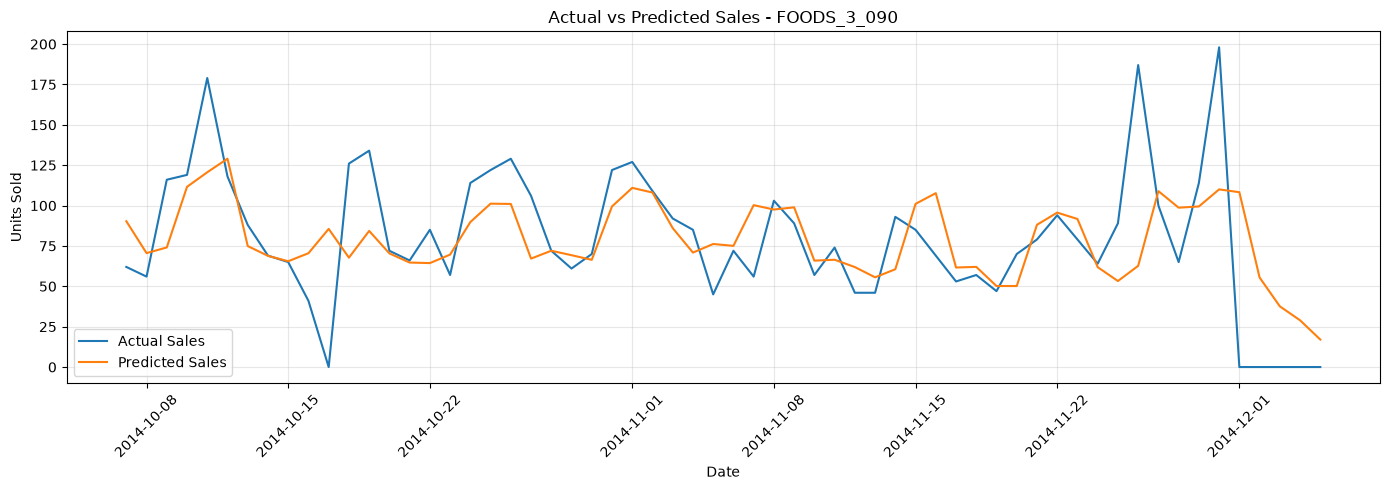

In [56]:
import matplotlib.pyplot as plt

# Select the worst-performing product
product_id = "FOODS_3_090"

product_results = val_results[
    val_results["item_id"] == product_id
].sort_values("date")

# Display the first 60 validation days
plot_data = product_results.head(60)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_data["date"],
    plot_data["sales"],
    label="Actual Sales"
)

plt.plot(
    plot_data["date"],
    plot_data["predicted_sales"],
    label="Predicted Sales"
)

plt.title(f"Actual vs Predicted Sales - {product_id}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
# Recreate validation results
val_results = val_data[
    ["item_id", "date", "sales"]
].copy()

# Add model predictions
val_results["predicted_sales"] = val_predictions

# Calculate prediction errors
val_results["absolute_error"] = abs(
    val_results["sales"] - val_results["predicted_sales"]
)

print("Validation results created successfully!")
print("Shape:", val_results.shape)

display(val_results.head())

Validation results created successfully!
Shape: (1415, 5)


,item_id,date,sales,predicted_sales,absolute_error
6259,FOODS_3_090,2014-10-07,62,90.307489,28.307489
6260,FOODS_3_120,2014-10-07,49,51.685934,2.685934
6261,FOODS_3_252,2014-10-07,33,43.940428,10.940428
6262,FOODS_3_586,2014-10-07,45,40.920159,4.079841
6263,FOODS_3_714,2014-10-07,14,25.479572,11.479572


In [58]:
variables = [
    "top_5_merged",
    "model_data",
    "train_data",
    "val_data",
    "test_data",
    "X_train",
    "rf_model",
    "val_predictions",
    "val_results"
]

for variable in variables:
    if variable in globals():
        print(variable, ": Available")
    else:
        print(variable, ": MISSING")

top_5_merged : Available
model_data : Available
train_data : Available
val_data : Available
test_data : Available
X_train : Available
rf_model : Available
val_predictions : Available
val_results : Available


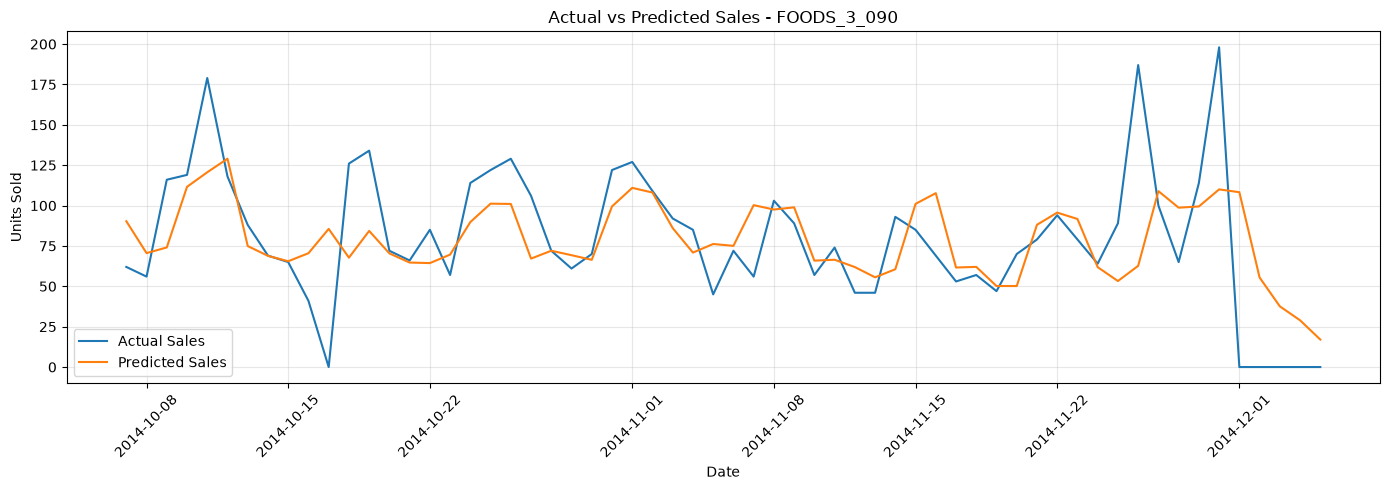

In [59]:
import matplotlib.pyplot as plt

# Select the product
product_id = "FOODS_3_090"

# Filter validation results
product_results = val_results[
    val_results["item_id"] == product_id
].sort_values("date")

# Select first 60 days
plot_data = product_results.head(60)

# Create graph
plt.figure(figsize=(14, 5))

plt.plot(
    plot_data["date"],
    plot_data["sales"],
    label="Actual Sales"
)

plt.plot(
    plot_data["date"],
    plot_data["predicted_sales"],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales - FOODS_3_090")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [60]:
# Create product identity features
X_train_v2 = X_train.copy()
X_val_v2 = X_val.copy()

# Convert product IDs into numeric columns
product_train = pd.get_dummies(
    train_data["item_id"],
    prefix="product",
    dtype=int
)

product_val = pd.get_dummies(
    val_data["item_id"],
    prefix="product",
    dtype=int
)

# Ensure validation columns match training
product_val = product_val.reindex(
    columns=product_train.columns,
    fill_value=0
)

# Add product columns
X_train_v2 = pd.concat(
    [X_train_v2, product_train],
    axis=1
)

X_val_v2 = pd.concat(
    [X_val_v2, product_val],
    axis=1
)

print("Original features:", X_train.shape[1])
print("Updated features:", X_train_v2.shape[1])

print("\nNew product features:")
print(product_train.columns.tolist())

print("\nMissing values:", X_train_v2.isna().sum().sum())

Original features: 18
Updated features: 23

New product features:
['product_FOODS_3_090', 'product_FOODS_3_120', 'product_FOODS_3_252', 'product_FOODS_3_586', 'product_FOODS_3_714']

Missing values: 0


In [61]:
# Train Random Forest with product identity features
rf_model_v2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model_v2.fit(X_train_v2, y_train)

# Predict validation sales
val_predictions_v2 = rf_model_v2.predict(X_val_v2)

# Calculate errors
mae_v2 = mean_absolute_error(y_val, val_predictions_v2)

rmse_v2 = np.sqrt(
    mean_squared_error(y_val, val_predictions_v2)
)

print("Model Comparison")
print("------------------------------")
print("Version 1 MAE:", round(mae, 2))
print("Version 2 MAE:", round(mae_v2, 2))

print()
print("Version 1 RMSE:", round(rmse, 2))
print("Version 2 RMSE:", round(rmse_v2, 2))

Model Comparison
------------------------------
Version 1 MAE: 11.46
Version 2 MAE: 11.41

Version 1 RMSE: 17.18
Version 2 RMSE: 17.11


In [62]:
# Calculate feature importance
feature_importance = pd.DataFrame({
    "feature": X_train_v2.columns,
    "importance": rf_model_v2.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

# Display top 10 features
display(feature_importance.head(10))

,feature,importance
9,rolling_mean_7,0.404738
6,lag_1,0.248026
0,day_of_week,0.078433
7,lag_7,0.074055
10,rolling_mean_28,0.036661
11,rolling_std_7,0.029847
8,lag_28,0.025328
12,rolling_std_28,0.022928
16,sell_price,0.021144
1,day_of_month,0.019928


,sales,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28,sell_price
sales,1.00,0.73,0.69,0.57,0.73,0.69,-0.09
lag_1,0.73,1.00,0.61,0.50,0.79,0.71,-0.09
lag_7,0.69,0.61,1.00,0.59,0.79,0.75,-0.09
lag_28,0.57,0.50,0.59,1.00,0.58,0.71,-0.09
rolling_mean_7,0.73,0.79,0.79,0.58,1.00,0.90,-0.11
rolling_mean_28,0.69,0.71,0.75,0.71,0.90,1.00,-0.12
sell_price,-0.09,-0.09,-0.09,-0.09,-0.11,-0.12,1.00


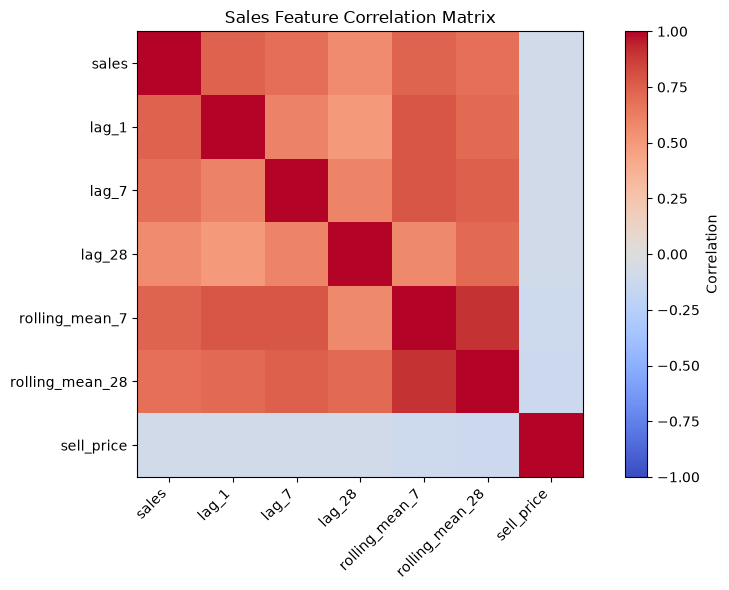

In [63]:
import matplotlib.pyplot as plt

# Select important numerical features
correlation_features = [
    "sales",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "sell_price"
]

# Calculate correlations using training data only
correlation_matrix = train_data[
    correlation_features
].corr()

# Display correlation matrix
display(correlation_matrix.round(2))

# Visualize correlation matrix
plt.figure(figsize=(9, 6))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_features)),
    correlation_features,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_features)),
    correlation_features
)

plt.title("Sales Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [64]:
# Add a sales trend feature
train_data["sales_trend"] = (
    train_data["rolling_mean_7"] -
    train_data["rolling_mean_28"]
)

val_data["sales_trend"] = (
    val_data["rolling_mean_7"] -
    val_data["rolling_mean_28"]
)

test_data["sales_trend"] = (
    test_data["rolling_mean_7"] -
    test_data["rolling_mean_28"]
)

print("Training trend summary:")
print(train_data["sales_trend"].describe().round(2))

print("\nMissing trend values:")
print(train_data["sales_trend"].isna().sum())
print(val_data["sales_trend"].isna().sum())
print(test_data["sales_trend"].isna().sum())

Training trend summary:
count    6259.00
mean        0.23
std        13.16
min      -115.64
25%        -4.04
50%         0.00
75%         4.04
max       136.86
Name: sales_trend, dtype: float64

Missing trend values:
0
0
0


In [65]:
# Create Version 3 feature datasets
X_train_v3 = X_train_v2.copy()
X_val_v3 = X_val_v2.copy()

# Add the new sales trend feature
X_train_v3["sales_trend"] = train_data["sales_trend"]
X_val_v3["sales_trend"] = val_data["sales_trend"]

# Train Random Forest Version 3
rf_model_v3 = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model_v3.fit(X_train_v3, y_train)

# Generate validation predictions
val_predictions_v3 = rf_model_v3.predict(X_val_v3)

# Calculate performance metrics
mae_v3 = mean_absolute_error(
    y_val, val_predictions_v3
)

rmse_v3 = np.sqrt(
    mean_squared_error(y_val, val_predictions_v3)
)

print("Random Forest Model Comparison")
print("--------------------------------")

print("Version 1 MAE:", round(mae, 2))
print("Version 2 MAE:", round(mae_v2, 2))
print("Version 3 MAE:", round(mae_v3, 2))

print()

print("Version 1 RMSE:", round(rmse, 2))
print("Version 2 RMSE:", round(rmse_v2, 2))
print("Version 3 RMSE:", round(rmse_v3, 2))

print("\nVersion 3 feature count:", X_train_v3.shape[1])

Random Forest Model Comparison
--------------------------------
Version 1 MAE: 11.46
Version 2 MAE: 11.41
Version 3 MAE: 11.44

Version 1 RMSE: 17.18
Version 2 RMSE: 17.11
Version 3 RMSE: 17.12

Version 3 feature count: 24


In [66]:
# Prepare test features for Version 2
X_test_v2 = X_test.copy()

# Create product identity columns
product_test = pd.get_dummies(
    test_data["item_id"],
    prefix="product",
    dtype=int
)

# Match the training product columns
product_test = product_test.reindex(
    columns=product_train.columns,
    fill_value=0
)

# Add product identity features
X_test_v2 = pd.concat(
    [X_test_v2, product_test],
    axis=1
)

# Ensure identical feature order
X_test_v2 = X_test_v2[X_train_v2.columns]

# Predict test sales using our best model
test_predictions_v2 = rf_model_v2.predict(X_test_v2)

# Calculate test performance
test_mae = mean_absolute_error(
    y_test, test_predictions_v2
)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions_v2)
)

print("Final Model: Random Forest V2")
print("-----------------------------")
print("Test MAE:", round(test_mae, 2))
print("Test RMSE:", round(test_rmse, 2))
print("Test records:", len(y_test))

Final Model: Random Forest V2
-----------------------------
Test MAE: 10.52
Test RMSE: 16.02
Test records: 1415


In [67]:
# Naive baseline on test data
test_naive_predictions = X_test["lag_1"]

test_naive_mae = mean_absolute_error(
    y_test, test_naive_predictions
)

test_naive_rmse = np.sqrt(
    mean_squared_error(y_test, test_naive_predictions)
)

# Calculate percentage improvement
mae_improvement = (
    (test_naive_mae - test_mae) / test_naive_mae
) * 100

print("Final Test Comparison")
print("------------------------------")

print("Naive Baseline MAE:", round(test_naive_mae, 2))
print("Random Forest V2 MAE:", round(test_mae, 2))

print()

print("Naive Baseline RMSE:", round(test_naive_rmse, 2))
print("Random Forest V2 RMSE:", round(test_rmse, 2))

print()

print("MAE Improvement:", round(mae_improvement, 2), "%")

Final Test Comparison
------------------------------
Naive Baseline MAE: 14.49
Random Forest V2 MAE: 10.52

Naive Baseline RMSE: 20.77
Random Forest V2 RMSE: 16.02

MAE Improvement: 27.41 %


In [ ]:
import joblib
from pathlib import Path

PROJECT_DIR = BASE_DIR

# Create models folder
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained Random Forest V2
model_path = MODEL_DIR / "demand_forecasting_rf_v2.joblib"
joblib.dump(rf_model_v2, model_path)

# Save feature names and order
feature_path = MODEL_DIR / "feature_columns_v2.joblib"
joblib.dump(X_train_v2.columns.tolist(), feature_path)

print("Model saved successfully!")
print("Model location:", model_path)
print("Features saved:", feature_path)
print("Number of features:", len(X_train_v2.columns))

In [70]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Load saved feature columns
loaded_features = joblib.load(feature_path)

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test_v2)

# Verify predictions match the original model
import numpy as np

predictions_match = np.allclose(
    test_predictions_v2,
    loaded_predictions
)

print("Model loaded successfully!")
print("Number of saved features:", len(loaded_features))
print("Feature order matches:", loaded_features == X_test_v2.columns.tolist())
print("Predictions match:", predictions_match)

print("\nFirst 5 predictions:")
print(np.round(loaded_predictions[:5], 2))

Model loaded successfully!
Number of saved features: 23
Feature order matches: True
Predictions match: True

First 5 predictions:
[82.33 40.39 47.21 50.31 30.08]


In [71]:
# Create the API directory
API_DIR = PROJECT_DIR / "api"

API_DIR.mkdir(parents=True, exist_ok=True)

print("API folder created successfully!")
print("Location:", API_DIR)
print("Folder exists:", API_DIR.exists())

API folder created successfully!
Location: C:\Users\admin\OneDrive\Enterprise_Demand_Forecasting\api
Folder exists: True


In [72]:
import json

# Select the first test record
sample_features = X_test_v2.iloc[0].to_dict()

# Create API request body
request_body = {
    "features": sample_features
}

# Display formatted JSON
print(json.dumps(request_body, indent=4))

{
    "features": {
        "day_of_week": 4.0,
        "day_of_month": 17.0,
        "week_of_year": 29.0,
        "month": 7.0,
        "year": 2015.0,
        "is_weekend": 0.0,
        "lag_1": 62.0,
        "lag_7": 120.0,
        "lag_28": 52.0,
        "rolling_mean_7": 64.28571428571429,
        "rolling_mean_28": 70.35714285714286,
        "rolling_std_7": 27.262393424607726,
        "rolling_std_28": 26.37930485944851,
        "was_zero_yesterday": 0.0,
        "is_event": 0.0,
        "snap_CA": 0.0,
        "sell_price": 1.48,
        "price_available": 1.0,
        "product_FOODS_3_090": 1.0,
        "product_FOODS_3_120": 0.0,
        "product_FOODS_3_252": 0.0,
        "product_FOODS_3_586": 0.0,
        "product_FOODS_3_714": 0.0
    }
}


In [73]:
# Save a reusable API test request
sample_request_path = API_DIR / "sample_request.json"

with open(sample_request_path, "w") as file:
    json.dump(request_body, file, indent=4)

print("Sample request saved!")
print("Location:", sample_request_path)
print("File exists:", sample_request_path.exists())

Sample request saved!
Location: C:\Users\admin\OneDrive\Enterprise_Demand_Forecasting\api\sample_request.json
File exists: True


In [74]:
# Create processed data directory
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save the feature-engineered dataset
processed_path = PROCESSED_DIR / "forecasting_features.csv"

model_data.to_csv(processed_path, index=False)

print("Processed dataset saved successfully!")
print("Location:", processed_path)
print("Rows:", model_data.shape[0])
print("Columns:", model_data.shape[1])
print("File exists:", processed_path.exists())

Processed dataset saved successfully!
Location: C:\Users\admin\OneDrive\Enterprise_Demand_Forecasting\data\processed\forecasting_features.csv
Rows: 9089
Columns: 31
File exists: True


In [75]:
import pandas as pd

# Load saved processed dataset
loaded_data = pd.read_csv(processed_path)

# Verify dataset
print("Dataset loaded successfully!")
print("Rows:", loaded_data.shape[0])
print("Columns:", loaded_data.shape[1])

print("\nAvailable products:")
print(loaded_data["item_id"].unique())

print("\nDate range:")
print("Start:", loaded_data["date"].min())
print("End:", loaded_data["date"].max())

print("\nMissing values in model features:")
print(loaded_data[X_train.columns].isna().sum().sum())

Dataset loaded successfully!
Rows: 9089
Columns: 31

Available products:
<StringArray>
['FOODS_3_090', 'FOODS_3_252', 'FOODS_3_586', 'FOODS_3_714', 'FOODS_3_120']
Length: 5, dtype: str

Date range:
Start: 2011-02-26
End: 2016-04-24

Missing values in model features:
0


In [76]:
# Create test prediction results
test_results = test_data[
    ["item_id", "date", "sales"]
].copy()

# Add Random Forest V2 predictions
test_results["predicted_sales"] = test_predictions_v2

# Calculate absolute prediction errors
test_results["absolute_error"] = (
    test_results["sales"] - test_results["predicted_sales"]
).abs()

# Save results for the dashboard
results_path = PROCESSED_DIR / "test_predictions.csv"

test_results.to_csv(results_path, index=False)

print("Test predictions saved successfully!")
print("Location:", results_path)
print("Total records:", len(test_results))
print("\nFirst 5 rows:")
print(test_results.head())

Test predictions saved successfully!
Location: C:\Users\admin\OneDrive\Enterprise_Demand_Forecasting\data\processed\test_predictions.csv
Total records: 1415

First 5 rows:
          item_id       date  sales  predicted_sales  absolute_error
7674  FOODS_3_090 2015-07-17     91        82.327760        8.672240
7675  FOODS_3_120 2015-07-17     40        40.388753        0.388753
7676  FOODS_3_252 2015-07-17     45        47.208884        2.208884
7677  FOODS_3_586 2015-07-17     52        50.310718        1.689282
7678  FOODS_3_714 2015-07-17     47        30.078095       16.921905
